# Monotonicity of the likelihood ratio $r_n(k)$

Static maximal-independent-set (jamming) model on $\{1,\dots,n\}$, with Padovan numbers $P_0=P_1=P_2=1$, $P_m=P_{m-2}+P_{m-3}$.

**Static model.** There are $P_{n+1}$ jammed configurations; those with $k$ particles are counted by
$$c_n(k)=\binom{k+1}{3k-n}\quad (n\ge 1),\qquad c_0(0)=c_{-1}(0)=1,$$
(and $0$ otherwise), so $u_n(k)=\mathbb P[N_n^{\rm stat}=k]=c_n(k)/P_{n+1}$. Admissible $k$: $\lceil n/3\rceil\le k\le\lfloor (n+1)/2\rfloor$.

**Auxiliary model.** Pick $J$ uniform on $\{1,\dots,n\}$, force a particle there, and fill the two residual intervals (sizes $j-2$ and $n-j-1$) independently with the static model:
$$q_n(k)=\frac1n\sum_{j=1}^{n}\ \sum_{a=0}^{k-1}\frac{c_{j-2}(a)}{P_{j-1}}\cdot\frac{c_{n-j-1}(k-1-a)}{P_{n-j}}.$$

**Explicit formula.**
$$\boxed{\,r_n(k)=\frac{q_n(k)}{u_n(k)}=\frac{P_{n+1}}{n\binom{k+1}{3k-n}}\sum_{j=1}^{n}\frac{1}{P_{j-1}P_{n-j}}\sum_{a=0}^{k-1}c_{j-2}(a)\,c_{n-j-1}(k-1-a)\,}$$

Everything is computed with exact rational arithmetic (`fractions.Fraction`), so the strict inequalities $r_n(k+1)>r_n(k)$ are verified exactly.

In [1]:
from fractions import Fraction
from math import comb
import numpy as np
import matplotlib.pyplot as plt

N_MAX = 73

# Padovan numbers: P0=P1=P2=1, P_m = P_{m-2} + P_{m-3}
P = [1, 1, 1]
for m in range(3, N_MAX + 5):
    P.append(P[m-2] + P[m-3])

def c(m, a):
    '''Number of jammed configurations on m sites with a particles.'''
    if m <= 0:                      # empty interval (m = 0) or "negative" interval (m = -1)
        return 1 if a == 0 else 0
    A = 3*a - m                     # number of 2's in the composition
    if a < 0 or A < 0:
        return 0
    return comb(a + 1, A)           # 0 automatically if A > a+1

def admissible(n):
    return range(-(-n // 3), (n + 1)//2 + 1)

def u(n, k):
    return Fraction(c(n, k), P[n + 1])

def q(n, k):
    total = Fraction(0)
    for j in range(1, n + 1):
        s = sum(c(j-2, a) * c(n-j-1, k-1-a) for a in range(0, k))
        total += Fraction(s, P[j-1] * P[n-j])
    return total / n

def r(n, k):
    return q(n, k) / u(n, k)

## Strict monotonicity of $r_n(k)$ for $1\le n\le 73$

In [2]:
min_gap = {}          # n -> min over k of r_n(k+1) - r_n(k)
n_pairs = 0
bad = []
R = {}
for n in range(1, N_MAX + 1):
    ks = list(admissible(n))
    R[n] = [r(n, k) for k in ks]
    gaps = [R[n][i+1] - R[n][i] for i in range(len(ks) - 1)]
    n_pairs += len(gaps)
    if any(g <= 0 for g in gaps):
        bad.append(n)
    if gaps:
        min_gap[n] = min(gaps)

pairs_72 = sum(len(R[n]) - 1 for n in range(1, 73))
print(f"Pairs (k, k+1) checked for n = 1..73 : {n_pairs}")
print(f"Pairs for n = 1..72 (paper reports 432): {pairs_72}")
print("Values of n where monotonicity FAILS :", bad if bad else "none")
print("r_n(k) strictly increasing for all 1 <= n <= 73:", not bad)

Pairs (k, k+1) checked for n = 1..73 : 444
Pairs for n = 1..72 (paper reports 432): 432
Values of n where monotonicity FAILS : none
r_n(k) strictly increasing for all 1 <= n <= 73: True


In [3]:
# A few exact values
for n in [4, 5, 10]:
    for k, val in zip(admissible(n), R[n]):
        print(f"n={n:2d}  k={k:2d}  r_n(k) = {val}  ~ {float(val):.6f}")
    print()

n= 4  k= 2  r_n(k) = 1  ~ 1.000000

n= 5  k= 2  r_n(k) = 4/5  ~ 0.800000
n= 5  k= 3  r_n(k) = 8/5  ~ 1.600000

n=10  k= 4  r_n(k) = 6934/7875  ~ 0.880508
n=10  k= 5  r_n(k) = 5666/4725  ~ 1.199153



## Plots

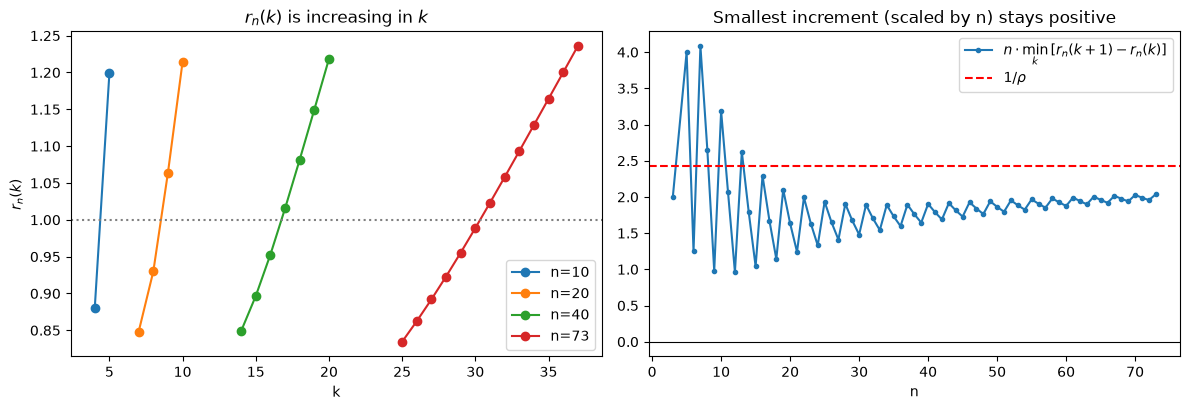

min over all (n,k) of n*(r_n(k+1)-r_n(k)) = 0.9611111111111111


In [4]:
p = 1.324717957244746                      # plastic number
rho = p**3 / (2*p + 3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for n in [10, 20, 40, 73]:
    ks = list(admissible(n))
    ax[0].plot(ks, [float(v) for v in R[n]], 'o-', label=f"n={n}")
ax[0].axhline(1, color='gray', ls=':')
ax[0].set_xlabel("k"); ax[0].set_ylabel(r"$r_n(k)$"); ax[0].set_title(r"$r_n(k)$ is increasing in $k$")
ax[0].legend()

ns = sorted(min_gap)
ax[1].plot(ns, [float(n * min_gap[n]) for n in ns], 'o-', ms=3, label=r"$n\cdot\min_k [r_n(k+1)-r_n(k)]$")
ax[1].axhline(0, color='k', lw=0.8)
ax[1].axhline(1/rho, color='r', ls='--', label=r"$1/\rho$")
ax[1].set_xlabel("n"); ax[1].set_title("Smallest increment (scaled by n) stays positive")
ax[1].legend()
plt.tight_layout(); plt.show()

print("min over all (n,k) of n*(r_n(k+1)-r_n(k)) =", float(min(n*g for n, g in min_gap.items())))